In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")

target_column = "target"

if target_column not in df.columns:
    raise ValueError(f"Target column '{target_column}' not found.")

df = df.drop_duplicates().dropna().reset_index(drop=True)

X_df = df.drop(columns=[target_column])
y = df[target_column].to_numpy()

X_df = pd.get_dummies(X_df, drop_first=False, dtype=float)
X = X_df.to_numpy(dtype=float)

if not np.isfinite(X).all():
    raise ValueError("Features contain infinite or invalid values.")

classes = np.unique(y)

if len(classes) < 2:
    raise ValueError("The target must contain at least two classes.")

print("Dataset shape:", X.shape)
print("Classes:", classes)
print("Class distribution:", pd.Series(y).value_counts().to_dict())

Dataset shape: (302, 13)
Classes: [0 1]
Class distribution: {1: 164, 0: 138}


In [3]:
rng = np.random.default_rng(42)

train_indices = []
test_indices = []

for cls in classes:
    class_indices = np.where(y == cls)[0]
    class_indices = rng.permutation(class_indices)

    if len(class_indices) < 2:
        raise ValueError(
            f"Class {cls} has too few observations for stratification."
        )

    n_test = max(1, int(round(0.20 * len(class_indices))))
    n_test = min(n_test, len(class_indices) - 1)

    test_indices.extend(class_indices[:n_test])
    train_indices.extend(class_indices[n_test:])

train_indices = rng.permutation(np.array(train_indices, dtype=int))
test_indices = rng.permutation(np.array(test_indices, dtype=int))

X_train_raw = X[train_indices]
X_test_raw = X[test_indices]
y_train = y[train_indices]
y_test = y[test_indices]

mean = X_train_raw.mean(axis=0)
std = X_train_raw.std(axis=0)
std[std == 0] = 1.0

X_train = (X_train_raw - mean) / std
X_test = (X_test_raw - mean) / std

print("\nTraining samples:", len(y_train))
print("Testing samples:", len(y_test))


Training samples: 241
Testing samples: 61


In [4]:
def pairwise_distances(A, B):
    """Calculate Euclidean distances without sklearn."""
    A_sq = np.sum(A * A, axis=1).reshape(-1, 1)
    B_sq = np.sum(B * B, axis=1).reshape(1, -1)

    squared = A_sq + B_sq - 2 * (A @ B.T)
    squared = np.maximum(squared, 0.0)

    return np.sqrt(squared)


def knn_predict(X_reference, y_reference, X_query, k):
    """Predict classes using manually calculated distances."""

    if k < 1 or k > len(y_reference):
        raise ValueError("k must be between 1 and the training size.")

    predictions = []

    batch_size = 128

    for start in range(0, len(X_query), batch_size):
        batch = X_query[start:start + batch_size]
        distances = pairwise_distances(batch, X_reference)

        for row in distances:
            candidate_indices = np.argpartition(row, k - 1)[:k]

            order = np.lexsort((candidate_indices, row[candidate_indices]))
            neighbors = candidate_indices[order]

            neighbor_labels = y_reference[neighbors]
            neighbor_distances = row[neighbors]

            vote_counts = np.array([
                np.sum(neighbor_labels == cls)
                for cls in classes
            ])

            highest_votes = np.max(vote_counts)
            tied_classes = classes[vote_counts == highest_votes]

            if len(tied_classes) == 1:
                prediction = tied_classes[0]
            else:
               
                total_distances = np.array([
                    np.sum(neighbor_distances[neighbor_labels == cls])
                    for cls in tied_classes
                ])

                best = np.lexsort((tied_classes, total_distances))[0]
                prediction = tied_classes[best]

            predictions.append(prediction)

    return np.asarray(predictions)


def manual_error_rate(y_true, y_pred):
    """Calculate misclassification rate manually."""
    mistakes = 0

    for actual, predicted in zip(y_true, y_pred):
        if actual != predicted:
            mistakes += 1

    return mistakes / len(y_true)

In [6]:
n_folds = 5
fold_rng = np.random.default_rng(123)

class_folds = {}

for cls in classes:
    indices = np.where(y_train == cls)[0]
    indices = fold_rng.permutation(indices)

    if len(indices) < n_folds:
        raise ValueError(
            f"Class {cls} has fewer than {n_folds} training samples. "
            "Reduce n_folds."
        )

    class_folds[cls] = np.array_split(indices, n_folds)

fold_indices = []

for fold_number in range(n_folds):
    validation_indices = np.concatenate([
        class_folds[cls][fold_number] for cls in classes
    ])
    fold_indices.append(fold_rng.permutation(validation_indices))

In [7]:
max_k = min(25, min(
    len(y_train) - len(fold_indices[i])
    for i in range(n_folds)
))

k_values = np.arange(1, max_k + 1, 2)

fold_error_rates = np.zeros((len(k_values), n_folds))

for fold_number in range(n_folds):
    validation_idx = fold_indices[fold_number]

    training_mask = np.ones(len(y_train), dtype=bool)
    training_mask[validation_idx] = False

    X_fold_train = X_train[training_mask]
    y_fold_train = y_train[training_mask]

    X_fold_valid = X_train[validation_idx]
    y_fold_valid = y_train[validation_idx]

    for k_index, k in enumerate(k_values):
        predictions = knn_predict(
            X_fold_train,
            y_fold_train,
            X_fold_valid,
            int(k)
        )

        fold_error_rates[k_index, fold_number] = manual_error_rate(
            y_fold_valid, predictions
        )

    print(f"Completed fold {fold_number + 1}/{n_folds}")

Completed fold 1/5
Completed fold 2/5
Completed fold 3/5
Completed fold 4/5
Completed fold 5/5


In [8]:
mean_errors = np.mean(fold_error_rates, axis=1)

if n_folds > 1:
    standard_errors = (
        np.std(fold_error_rates, axis=1, ddof=1)
        / np.sqrt(n_folds)
    )
else:
    standard_errors = np.zeros(len(k_values))

best_index = int(np.argmin(mean_errors))
minimum_error = mean_errors[best_index]
best_k_min_error = int(k_values[best_index])


threshold = minimum_error + standard_errors[best_index]

eligible_indices = np.where(mean_errors <= threshold)[0]
selected_index = int(eligible_indices[0])
selected_k = int(k_values[selected_index])

results = pd.DataFrame({
    "k": k_values,
    "Mean_CV_Error": mean_errors,
    "Standard_Error": standard_errors,
    "Mean_CV_Accuracy": 1 - mean_errors
})

print("\nCross-validation results:")
print(results.round(4).to_string(index=False))

print("\nLowest mean CV error k:", best_k_min_error)
print("Minimum mean CV error:", round(minimum_error, 4))
print("One-standard-error threshold:", round(threshold, 4))
print("Selected k:", selected_k)


Cross-validation results:
 k  Mean_CV_Error  Standard_Error  Mean_CV_Accuracy
 1         0.2698          0.0221            0.7302
 3         0.2240          0.0256            0.7760
 5         0.1870          0.0332            0.8130
 7         0.1951          0.0205            0.8049
 9         0.2074          0.0366            0.7926
11         0.1949          0.0438            0.8051
13         0.1867          0.0432            0.8133
15         0.2032          0.0412            0.7968
17         0.1948          0.0514            0.8052
19         0.1782          0.0447            0.8218
21         0.1866          0.0370            0.8134
23         0.1991          0.0369            0.8009
25         0.2115          0.0349            0.7885

Lowest mean CV error k: 19
Minimum mean CV error: 0.1782
One-standard-error threshold: 0.223
Selected k: 5


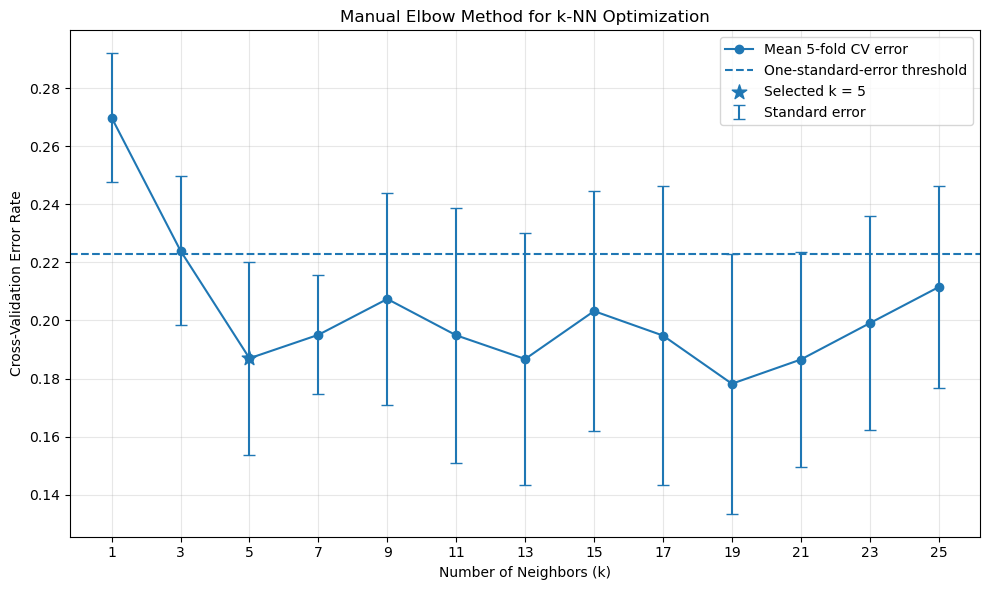

In [9]:
plt.figure(figsize=(10, 6))

plt.plot(
    k_values,
    mean_errors,
    marker="o",
    linestyle="-",
    label="Mean 5-fold CV error"
)

plt.errorbar(
    k_values,
    mean_errors,
    yerr=standard_errors,
    fmt="none",
    capsize=4,
    label="Standard error"
)

plt.axhline(
    threshold,
    linestyle="--",
    label="One-standard-error threshold"
)

plt.scatter(
    [selected_k],
    [mean_errors[selected_index]],
    s=120,
    marker="*",
    label=f"Selected k = {selected_k}"
)

plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Cross-Validation Error Rate")
plt.title("Manual Elbow Method for k-NN Optimization")
plt.xticks(k_values)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
final_predictions = knn_predict(
    X_train, y_train, X_test, selected_k
)

test_error = manual_error_rate(y_test, final_predictions)
test_accuracy = 1 - test_error

print("\nFinal test results")
print("------------------")
print("Selected k:", selected_k)
print("Test error rate:", round(test_error, 4))
print("Test accuracy:", round(test_accuracy, 4))


Final test results
------------------
Selected k: 5
Test error rate: 0.1311
Test accuracy: 0.8689



Manual confusion matrix:
          Predicted 0  Predicted 1
Actual 0           23            5
Actual 1            3           30


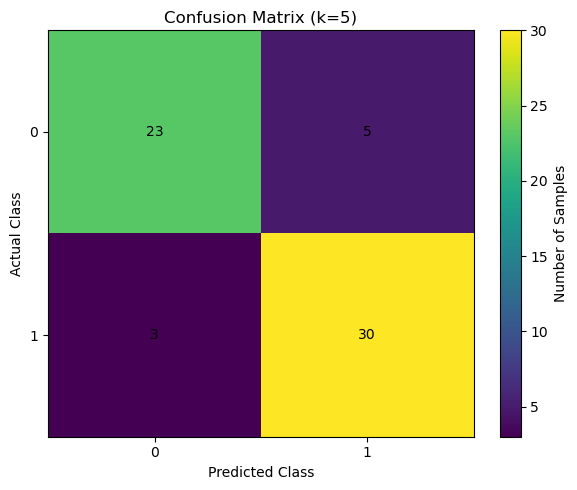

In [11]:
confusion = np.zeros((len(classes), len(classes)), dtype=int)

for actual, predicted in zip(y_test, final_predictions):
    actual_index = np.where(classes == actual)[0][0]
    predicted_index = np.where(classes == predicted)[0][0]
    confusion[actual_index, predicted_index] += 1

confusion_df = pd.DataFrame(
    confusion,
    index=[f"Actual {cls}" for cls in classes],
    columns=[f"Predicted {cls}" for cls in classes]
)

print("\nManual confusion matrix:")
print(confusion_df)

plt.figure(figsize=(6, 5))
plt.imshow(confusion, interpolation="nearest", aspect="auto")
plt.title(f"Confusion Matrix (k={selected_k})")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(range(len(classes)), classes)
plt.yticks(range(len(classes)), classes)

for i in range(len(classes)):
    for j in range(len(classes)):
        plt.text(j, i, str(confusion[i, j]),
                 ha="center", va="center")

plt.colorbar(label="Number of Samples")
plt.tight_layout()
plt.show()

In [12]:
results.to_csv("manual_knn_elbow_results.csv", index=False)

pd.DataFrame({
    "Actual": y_test,
    "Predicted": final_predictions
}).to_csv("manual_knn_elbow_test_predictions.csv", index=False)

print("\nSaved:")
print("- manual_knn_elbow_results.csv")
print("- manual_knn_elbow_test_predictions.csv")



Saved:
- manual_knn_elbow_results.csv
- manual_knn_elbow_test_predictions.csv
